In [33]:
import joblib
import h5py
import numpy as np
from utils import save, load
from library import *
import gc
from continuous_process_library_terms import *
from commons_identify_models import *
import copy
import jax
import jax.numpy as jnp
from jax_cfd.base import boundaries, grids, pressure, finite_differences as fd
import jax_cfd.base as cfd
import jax_cfd.base.grids as grids
import jax_cfd.spectral as spectral
import numpy as np
#import xarray 
#import xarray as xr
import dataclasses
import time
jax.config.update("jax_enable_x64", True)
import numpy as np
import os, joblib
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from numpy.polynomial.chebyshev import chebvander

import contextlib
import joblib
from tqdm import tqdm

@contextlib.contextmanager
def tqdm_joblib(tqdm_object):
    """Context manager to patch joblib to report into tqdm progress bar given as argument"""
    class TqdmBatchCompletionCallback(joblib.parallel.BatchCompletionCallBack):
        def __call__(self, *args, **kwargs):
            tqdm_object.update(n=self.batch_size)
            return super().__call__(*args, **kwargs)

    old_batch_callback = joblib.parallel.BatchCompletionCallBack
    joblib.parallel.BatchCompletionCallBack = TqdmBatchCompletionCallback
    try:
        yield tqdm_object
    finally:
        joblib.parallel.BatchCompletionCallBack = old_batch_callback
        tqdm_object.close()

In [34]:
# --- NEW CELL (Call this 'Cell 2 - New') ---
# Run this cell INSTEAD of the old cells 2, 3, and 4.

print("Loading preprocessed arrays from .npz file...")

# Path to the file you just saved
load_path = '/storage/scratch1/2/ashelestov3/preprocessed_4096_data.npz'

# Load the data from the .npz file
data = np.load(load_path)

# Re-create your variables from the saved data
U = data['U']
V = data['V']
P = data['P']
B = data['B']
W = data['W']
x = data['x']
y = data['y']
t = data['t']

# IMPORTANT: You must also re-define the parameters from your old Cell 3,
# as the rest of your notebook depends on them.
size_x = 4096
size_y = 1536
inner_steps = 1
outer_steps = 286

Lx =  4
Ly = 1
Nx = size_x
Ny = size_y
Nt = outer_steps
dx = Lx/(size_x-1)
dy = Ly/(size_y-1)
Lt = 1.99
dt = 200/286*1e-3
Rayleigh = 1e8
Prandtl = 1
kappa = (Rayleigh * Prandtl)**(-1/2)
print("Done loading!")
print("U shape:", U.shape)
print("P shape:", P.shape)
print("dx:", dx)
print("dt:", dt)

Loading preprocessed arrays from .npz file...
Done loading!
U shape: (4096, 1536, 286)
P shape: (4096, 1536, 286)
dx: 0.0009768009768009768
dt: 0.0006993006993006993


In [35]:
import numpy as np
import joblib
from joblib import Parallel, delayed
from tqdm import tqdm
from numpy.polynomial.chebyshev import chebvander

# ==========================================
# PART 1: GRID & FILTER SETUP (Formerly Cell 5)
# ==========================================
print("Setting up Chebyshev grids and filter matrices...")

# Parameters
delta = 0.0001
Nx_out = 4096
Ny_out = 1536
Lx = 4.0   # x ∈ (0,4)
Ly = 1.0   # y ∈ (0,1)

# 1. Define Chebyshev nodes mapped to (0, 1)
Ny = Ny_out
# y_raw is likely already linspace or Chebyshev nodes in ascending order
y_nodes_in = y_raw 
perm = np.arange(Ny) # Identity mapping (do nothing)

# 2. Build horizontal Fourier-space Gaussian filter
def _build_Gx(n, Lx, delta):
    kx = np.fft.rfftfreq(n, d=Lx / n) * 2 * np.pi
    return np.exp(-kx**2 * delta**2 / 24.0)[:, None]

# 3. Build Chebyshev-space Gaussian smoothing matrix
def _build_S(x_cheb, delta, Ly):
    Nyc = x_cheb.size
    delta_scaled = delta / Ly
    xk = x_cheb[None, :]
    xj = x_cheb[:, None]
    G = np.exp(-6.0 * ((xk - xj) ** 2) / (delta_scaled ** 2))
    w = np.sqrt(x_cheb * (1.0 - x_cheb)) * np.pi / Nyc
    WG = w[None, :] * G
    S = WG / WG.sum(axis=1, keepdims=True)
    return S

# 4. Build projection/interpolation matrix
def _build_P(x_cheb, y_out, Ly):
    Nyc = x_cheb.size
    t_out = 2.0 * (y_out / Ly) - 1.0
    t_out = np.clip(t_out, -1.0, 1.0)
    t_nodes = 2.0 * x_cheb - 1.0
    V_nodes = chebvander(t_nodes, Nyc - 1)
    V_tgt = chebvander(t_out, Nyc - 1)
    return np.linalg.solve(V_nodes.T, V_tgt.T).T

# 5. Combined filtering + interpolation function
def filter_interpolate_fast(u_xy_sorted, x_cheb, delta, Lx, Ly, Nx_out, Ny_out, S, P_p, Gx_out):
    Nyc = u_xy_sorted.shape[1]
    uh_in = np.fft.rfft(u_xy_sorted, axis=0)
    m_in = uh_in.shape[0]
    m_out = Gx_out.shape[0]
    uh_out = np.zeros((m_out, Nyc), dtype=uh_in.dtype)
    m_keep = min(m_in, m_out)
    uh_out[:m_keep, :] = uh_in[:m_keep, :]
    u_down_x = np.fft.irfft(uh_out * Gx_out, n=Nx_out, axis=0)
    u_filtered_y = u_down_x @ S.T
    u_filt = u_filtered_y @ P_p.T
    return u_filt

# Build Matrices
y_out = np.linspace(0, Ly, Ny_out)
S = _build_S(x_cheb, delta, Ly)
P_p = _build_P(x_cheb, y_out, Ly)
Gx_out = _build_Gx(Nx_out, Lx, delta)

print("Grids and matrices built.")

# ==========================================
# PART 2: EXACT CHUNKED FILTERING (FIXED)
# ==========================================
import numpy as np
import joblib
from joblib import Parallel, delayed
from tqdm import tqdm

# Initialize Output Arrays
dtype_u = U.dtype
dtype_tau = np.result_type(dtype_u, dtype_u)

u_filt = np.empty((Nx_out, Ny_out, Nt), dtype=dtype_u)
v_filt = np.empty((Nx_out, Ny_out, Nt), dtype=dtype_u)
p_filt = np.empty((Nx_out, Ny_out, Nt), dtype=dtype_u)
b_filt = np.empty((Nx_out, Ny_out, Nt), dtype=dtype_u)
w_filt = np.empty((Nx_out, Ny_out, Nt), dtype=dtype_u)
tau_xx = np.empty((Nx_out, Ny_out, Nt), dtype=dtype_tau)
tau_xy = np.empty((Nx_out, Ny_out, Nt), dtype=dtype_tau)
tau_yy = np.empty((Nx_out, Ny_out, Nt), dtype=dtype_tau)

def chunked_matmul(Matrix, Field, n_chunks=8):
    """
    Computes Result = Matrix @ Field.T
    
    Matrix shape: (Rows, Cols) -> (1536, 1536)
    Field shape:  (Nx, Cols)   -> (4096, 1536)
    
    We want to apply the matrix to the columns of Field.
    Mathematically: Result = (Matrix @ Field.T).T
    """
    # Transpose Field so the dimension to be multiplied (1536) is in the rows
    # Field_T shape: (1536, 4096)
    Field_T = Field.T 
    
    n_rows_out = Matrix.shape[0]
    n_cols_in = Matrix.shape[1]
    
    # Safety check
    if Field_T.shape[0] != n_cols_in:
        raise ValueError(f"Shape mismatch: Matrix expects {n_cols_in} rows, got {Field_T.shape[0]}")

    chunk_size = (n_rows_out + n_chunks - 1) // n_chunks
    
    # Prepare output buffer (Rows, Nx) -> (1536, 4096)
    Result_T = np.empty((n_rows_out, Field_T.shape[1]), dtype=Field.dtype)
    
    for i in range(n_chunks):
        start = i * chunk_size
        end = min((i + 1) * chunk_size, n_rows_out)
        if start >= end: break
        
        # Slice the Matrix rows
        M_chunk = Matrix[start:end, :]
        
        # Compute: (Chunk, 1536) @ (1536, 4096) -> (Chunk, 4096)
        Result_T[start:end, :] = M_chunk @ Field_T
        
    # Transpose back to (4096, 1536)
    return Result_T.T

def filter_timestep_robust(ti):
    # 1. Load full frame
    u_i = U[:, perm, ti]
    v_i = V[:, perm, ti]
    p_i = P[:, perm, ti]
    b_i = B[:, perm, ti]
    w_i = W[:, perm, ti]

    # 2. Filter X-direction (FFT)
    def filter_x(field):
        Nyc = field.shape[1]
        uh_in = np.fft.rfft(field, axis=0)
        m_out = Gx_out.shape[0]
        uh_out = np.zeros((m_out, Nyc), dtype=uh_in.dtype)
        m_keep = min(uh_in.shape[0], m_out)
        uh_out[:m_keep, :] = uh_in[:m_keep, :]
        # Returns (Nx, Ny)
        return np.fft.irfft(uh_out * Gx_out, n=Nx_out, axis=0)

    u_x = filter_x(u_i)
    v_x = filter_x(v_i)
    p_x = filter_x(p_i)
    b_x = filter_x(b_i)
    w_x = filter_x(w_i)
    
    u2_x = filter_x(u_i**2)
    uv_x = filter_x(u_i*v_i)
    v2_x = filter_x(v_i**2)

    # 3. Filter Y-direction using CHUNKED Matrix Multiply
    def apply_y_filter(field_x):
        # Step 1: Smooth (S @ field.T)
        # field_x is (4096, 1536). S is (1536, 1536).
        smoothed = chunked_matmul(S, field_x, n_chunks=4)
        
        # Step 2: Interpolate (P @ smoothed.T)
        # smoothed is (4096, 1536). P_p is (1536, 1536).
        final = chunked_matmul(P_p, smoothed, n_chunks=4)
        return final

    u_f = apply_y_filter(u_x)
    v_f = apply_y_filter(v_x)
    p_f = apply_y_filter(p_x)
    b_f = apply_y_filter(b_x)
    w_f = apply_y_filter(w_x)
    
    u2_f = apply_y_filter(u2_x)
    uv_f = apply_y_filter(uv_x)
    v2_f = apply_y_filter(v2_x)

    # 4. Calc Stresses
    txx = u2_f - u_f**2
    txy = uv_f - u_f * v_f
    tyy = v2_f - v_f**2

    return ti, u_f, v_f, p_f, b_f, w_f, txx, txy, tyy

# Run Parallel Processing
print("Starting Fixed Chunked Filtering...")
N_JOBS = max(1, joblib.cpu_count() - 2) 

results = Parallel(n_jobs=N_JOBS, prefer="processes")(
    delayed(filter_timestep_robust)(ti) for ti in tqdm(range(Nt))
)

# Collect Results
print("Collecting results...")
for ti, u_f, v_f, p_f, b_f, w_f, txx, txy, tyy in results:
    u_filt[..., ti] = u_f
    v_filt[..., ti] = v_f
    p_filt[..., ti] = p_f
    b_filt[..., ti] = b_f
    w_filt[..., ti] = w_f
    tau_xx[..., ti] = txx
    tau_xy[..., ti] = txy
    tau_yy[..., ti] = tyy

# Final Stacks
u_bar = np.stack([u_filt, v_filt], axis=3)
row1 = np.stack([tau_xx, tau_xy], axis=3)
row2 = np.stack([tau_xy, tau_yy], axis=3)
tau  = np.stack([row1,  row2],  axis=4)

print("Processing complete.")
print("Filtering complete. Variables 'u_filt', 'v_filt', and 'tau' are ready.")

Setting up Chebyshev grids and filter matrices...
Grids and matrices built.
Starting Fixed Chunked Filtering...


100%|██████████| 286/286 [00:26<00:00, 10.75it/s] 


Processing complete.
Filtering complete. Variables 'u_filt', 'v_filt', and 'tau' are ready.


In [36]:
v_filt=v_filt[5:-5,5:-5,:]
u_filt=u_filt[5:-5,5:-5,:]
b_filt=b_filt[5:-5,5:-5,:]
p_filt=p_filt[5:-5,5:-5,:]
w_filt=w_filt[5:-5,5:-5,:]

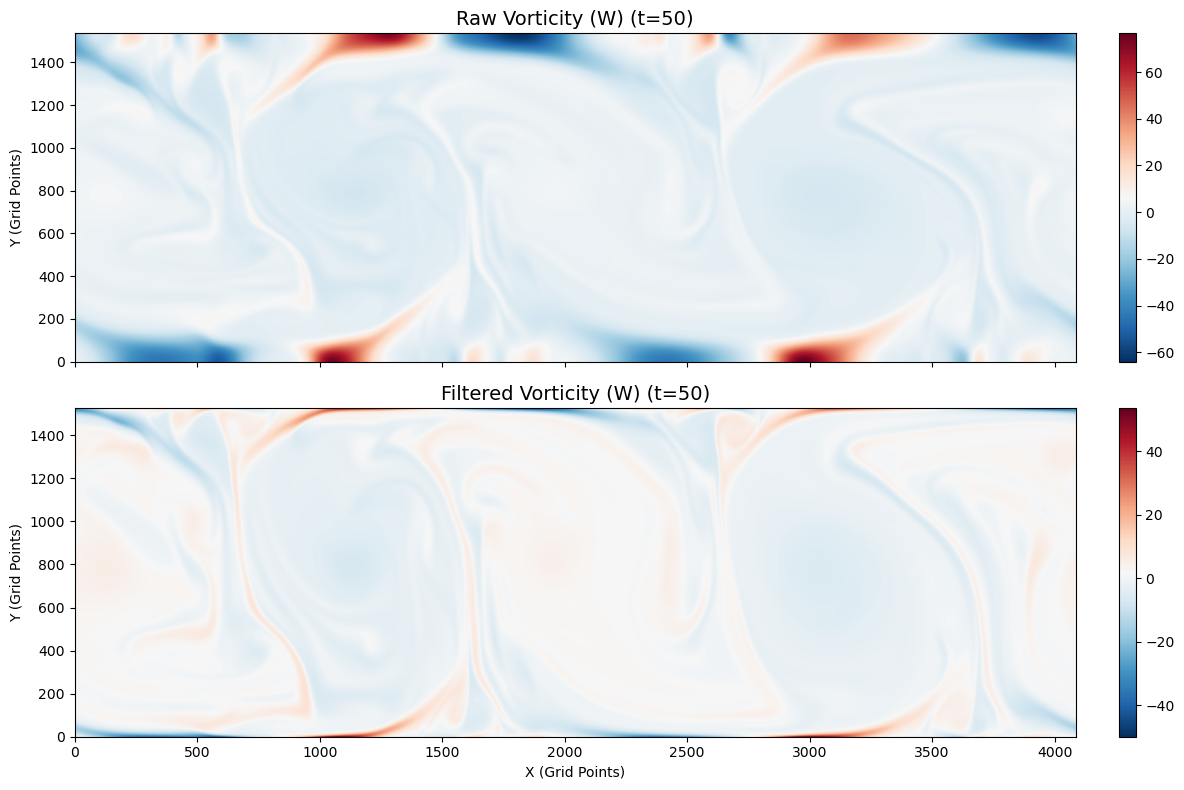

Zooming in on a small section...


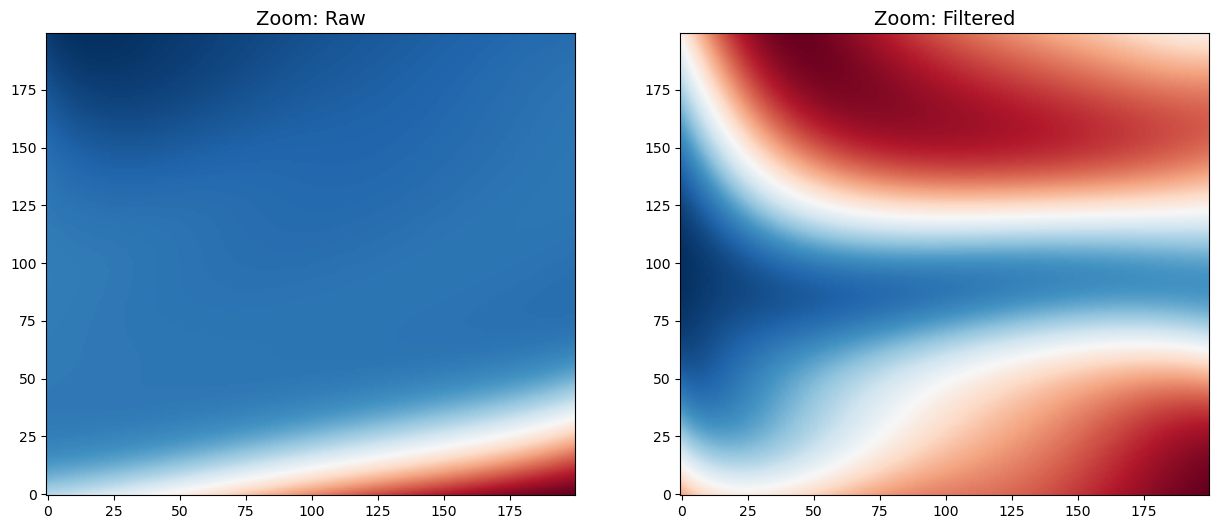

In [37]:
import matplotlib.pyplot as plt

# === Parameters ===
field_name = 'w'      # Choose: 'u', 'v', 'p', 'b', or 'w'
time_step_idx = 50    # Choose a timestep to visualize (e.g., 50)
cmap = 'RdBu_r'       # Colormap (Red-Blue is good for velocity/divergence)

# === Select Data ===
if field_name == 'u':
    raw_data = U[:, perm, time_step_idx] # Note: Apply 'perm' to raw data to match grid
    filt_data = u_filt[:, :, time_step_idx]
    title_txt = "Horizontal Velocity (U)"
elif field_name == 'v':
    raw_data = V[:, perm, time_step_idx]
    filt_data = v_filt[:, :, time_step_idx]
    title_txt = "Vertical Velocity (V)"
elif field_name == 'b':
    raw_data = B[:, perm, time_step_idx]
    filt_data = b_filt[:, :, time_step_idx]
    title_txt = "Buoyancy (B)"
elif field_name == 'p':
    raw_data = P[:, perm, time_step_idx]
    filt_data = p_filt[:, :, time_step_idx]
    title_txt = "Pressure (P)"
elif field_name == 'w':
    raw_data = W[:, perm, time_step_idx]
    filt_data = w_filt[:, :, time_step_idx]
    title_txt = "Vorticity (W)"

# === Plotting ===
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Plot Raw
# We transpose (.T) so that X is horizontal and Y is vertical
im1 = axes[0].imshow(raw_data.T, origin='lower', cmap=cmap, aspect='auto')
axes[0].set_title(f"Raw {title_txt} (t={time_step_idx})", fontsize=14)
axes[0].set_ylabel("Y (Grid Points)")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

# Plot Filtered
im2 = axes[1].imshow(filt_data.T, origin='lower', cmap=cmap, aspect='auto')
axes[1].set_title(f"Filtered {title_txt} (t={time_step_idx})", fontsize=14)
axes[1].set_ylabel("Y (Grid Points)")
axes[1].set_xlabel("X (Grid Points)")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

# === Optional: Zoom in to see the smoothing ===
# Use this to see the pixel-level difference
print("Zooming in on a small section...")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Zoom slice
ys, ye = 100, 300  # Y-slice
xs, xe = 1000, 1200 # X-slice

im3 = axes[0].imshow(raw_data[xs:xe, ys:ye].T, origin='lower', cmap=cmap, aspect='auto')
axes[0].set_title("Zoom: Raw", fontsize=14)

im4 = axes[1].imshow(filt_data[xs:xe, ys:ye].T, origin='lower', cmap=cmap, aspect='auto')
axes[1].set_title("Zoom: Filtered", fontsize=14)

plt.show()

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import numpy as np # Needed for array manipulation, e.g., range

# --- 1. Animation Setup and Parameters ---
FIELD_NAME = 'w'         # Choose: 'u', 'v', 'p', 'b', or 'w'
CMAP = 'RdBu_r'          # Colormap
SAVE_PATH = '/storage/scratch1/2/ashelestov3/anim/animated_fields.gif'
FPS = 10                 # Frames per second for the final GIF
INTERVAL_MS = dt # Delay in ms between frames (100ms for 10 FPS)
DPI_SETTING = 300

# --- 2. Data Initialization (Assuming your data is already loaded) ---
# NOTE: Replace 'W' and 'w_filt' with your actual loaded data arrays.
# I'm using placeholder data that mimics the structure: (X, Y, Time)
# Total number of time steps will be N_FRAMES
N_FRAMES = 286 # Adjust this based on the size of your time dimension
X_SIZE, Y_SIZE = 4096, 1536

# --- Placeholder Data (Replace with your actual loaded data) ---
# Assuming these are loaded from your .npz file (e.g., W = data['W'])
'''try:
    # If W, w_filt, and perm are not defined, create placeholders
    W = np.random.rand(X_SIZE, Y_SIZE, N_FRAMES)
    w_filt = np.sin(W)
    perm = np.arange(Y_SIZE) # A simple permutation array if needed
except NameError:
    print("WARNING: Data arrays (W, w_filt, perm) not found. Using placeholder data.")
    W = np.random.rand(X_SIZE, Y_SIZE, N_FRAMES)
    w_filt = np.sin(W)''
    perm = np.arange(Y_SIZE)'''
# -------------------------------------------------------------------
print(W.shape)
# Set Field and Title based on the selection
if FIELD_NAME == 'w':
    DATA_RAW = W
    DATA_FILT = w_filt
    TITLE_TXT = "Vorticity (W)"
# Add other 'elif' conditions here for 'u', 'v', etc., if you change FIELD_NAME
# For this example, we assume FIELD_NAME='w' is used.

# --- 3. Plotting Setup ---
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Determine the global min/max for the colorbar to keep it constant across frames
# This is crucial for a meaningful animation
v_min = min(np.min(DATA_RAW), np.min(DATA_FILT))
v_max = max(np.max(DATA_RAW), np.max(DATA_FILT))

# Initialize the first frame (time_step_idx = 0)
initial_raw_data = DATA_RAW[:, perm, 0]
initial_filt_data = DATA_FILT[:, :, 0]

# Initialize Raw Plot
im1 = axes[0].imshow(
    initial_raw_data.T, 
    origin='lower', 
    cmap=CMAP, 
    aspect='auto', 
    vmin=v_min, 
    vmax=v_max
)
axes[0].set_ylabel("Y (Grid Points)")
cbar1 = plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)
title1 = axes[0].set_title(f"Raw {TITLE_TXT} (t=0)", fontsize=14)

# Initialize Filtered Plot
im2 = axes[1].imshow(
    initial_filt_data.T, 
    origin='lower', 
    cmap=CMAP, 
    aspect='auto', 
    vmin=v_min, 
    vmax=v_max
)
axes[1].set_ylabel("Y (Grid Points)")
axes[1].set_xlabel("X (Grid Points)")
cbar2 = plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)
title2 = axes[1].set_title(f"Filtered {TITLE_TXT} (t=0)", fontsize=14)

plt.tight_layout()

# --- 4. The Animation Function ---
def animate(i):
    """
    Updates the plot data for the i-th time step.
    'i' is the frame index (0 to N_FRAMES-1).
    """
    time_step_idx = i # The frame index is our time step

    # 1. Select the data for the current time step
    raw_frame_data = DATA_RAW[:, perm, time_step_idx]
    filt_frame_data = DATA_FILT[:, :, time_step_idx]

    # 2. Update the image data (Note: We use .T to transpose)
    im1.set_data(raw_frame_data.T)
    im2.set_data(filt_frame_data.T)

    # 3. Update the titles
    title1.set_text(f"Raw {TITLE_TXT} (t={50+dt*time_step_idx})")
    title2.set_text(f"Filtered {TITLE_TXT} (t={50+dt*time_step_idx})")

    # Return the updated artists (plot elements)
    return im1, im2, title1, title2

# --- 5. Create and Save the Animation ---
print(f"Creating animation with {N_FRAMES} frames...")
anim = FuncAnimation(
    fig, 
    animate, 
    frames=N_FRAMES, 
    interval=INTERVAL_MS, 
    blit=True, 
    repeat=False # Set to True to loop
)

print(f"Saving animation to {SAVE_PATH} (FPS: {FPS})...")

try:
    # Requires 'pillow' or 'ffmpeg' to be installed. 'pillow' is best for GIF.
    anim.save(
        SAVE_PATH, 
        writer='pillow', 
        fps=FPS,
        dpi=DPI_SETTING
    )
    print("✅ Animation saved successfully!")
except Exception as e:
    print(f"❌ Error during saving: {e}")
    print("Ensure you have the 'pillow' library installed: `pip install pillow`")

plt.close(fig) # Close the figure to prevent displaying it in a window

In [38]:
dx=x[1]-x[0]
dy=y[1]-y[0]
print(dx, dy)

0.0009765625 2.0916400060855267e-06


In [39]:
print(Lx/Nx_out)
print(Ly/Ny_out)

0.0009765625
0.0006510416666666666


In [40]:
# Define Observables for SPIDER/PySINDy
uobs = Observable(string='u', rank=1)
pobs = Observable(string='p', rank=0)
bobs = Observable(string='b', rank=0) 
zobs = Observable(string='z̄', rank=1)
wobs = Observable(string='w', rank=0)
Tobs = Observable(string='T', rank=2, can_commute_indices = True, antisymmetric = False)
observables = [uobs, bobs, pobs, zobs, wobs, Tobs]

# --- FIX START ---
# We rename 'x' and 'z' to 'vec_x' and 'vec_z' to avoid overwriting your global grid coordinates
vec_z = np.full(b_filt.shape, 1)
vec_x = np.full(b_filt.shape, 0) 

# Create the unit vector field (0, 1) everywhere
unit_vect = np.concatenate([vec_x[:, :, :, np.newaxis], vec_z[:, :, :, np.newaxis]], axis=3)
# --- FIX END ---

# Create Data Dictionary
data_dict = {'u' : u_bar, 'b' : b_filt, 'p' : p_filt, 'z̄' : unit_vect, 'w' : w_filt, 'T' : tau}
print("Data dictionary prepared.")
print("u_filt shape:", u_filt.shape)

# Fix random seed
np.random.seed(1)

world_size = np.array(p_filt.shape)
pad = 0

# Use the global dx, dy, dt variables (ensure these are loaded!)
dxs = [dx, dy, dt]

# Initial setup of SRDataset
srd = SRDataset(world_size=world_size, data_dict=data_dict, observables=observables, dxs=dxs, 
                irreps=SRDataset.all_rank2_irreps())

# Initialize libraries
srd.make_libraries(max_complexity=3)
for irrep in srd.irreps:
    print(irrep, ":", len(srd.libs[irrep].terms))

import os
 
# Parallel Processing Setup
num_cores = os.cpu_count()
print(f"Logical CPU cores available: {num_cores}")

Ndomainz = len(srd.libs[srd.irreps[1]].terms) * 10
num_processorz = max(1, num_cores - 4) # Ensure at least 1 processor
Ndomainz_rounded = num_processorz * round(Ndomainz / num_processorz)

print(f"Terms: {len(srd.libs[srd.irreps[1]].terms)}")
print(f"Processors: {num_processorz}")
print(f"Domains: {Ndomainz_rounded}")

# Domain Construction
dom_width = 64 
dom_time = 40 * 200 // 236 
pad = 0

srd.make_domains(ndomains=Ndomainz_rounded, domain_size=[dom_width, dom_width, dom_time], pad=pad)
srd.make_weights(m=16, qmax=0)
srd.set_LT_scale(L=dx*dom_width, T=dt*dom_time) 

# Build Library Matrices
srd.make_library_matrices(debug=False, parallel=True, num_processors=num_processorz)

Data dictionary prepared.
u_filt shape: (4086, 1526, 286)
Rank 0 : 74
Rank 1 : 79
Antisymmetric rank 2 : 24
Symmetric trace-free rank 2 : 40
Logical CPU cores available: 128
Terms: 79
Processors: 124
Domains: 744


In [27]:
T_αα, T_αα · b, T_αα · p, T_αα · w, ∂t T_αα, b, b · b, b · b · b, b · b · p, b · b · w, b · ∂t b, b · p, b · p · p, b · p · w, 
b · ∂t p, b · u_α · u_α, b · u_α · z̄_α, b · ∂α u_α, b · w, b · w · w, b · ∂t w, b · z̄_α · z̄_α, b · ∂α z̄_α, ∂α b · u_α, 
∂α b · z̄_α, ∂α² b, ∂t b, ∂t b · p, ∂t b · w, ∂t² b, p, p · p, p · p · p, p · p · w, p · ∂t p, p · u_α · u_α, p · u_α · z̄_α,
p · ∂α u_α, p · w, p · w · w, p · ∂t w, p · z̄_α · z̄_α, p · ∂α z̄_α, ∂α p · u_α, ∂α p · z̄_α, ∂α² p, ∂t p, ∂t p · w, ∂t² p,
u_α · u_α, u_α · u_α · w, u_α · ∂t u_α, u_α · w · z̄_α, u_α · ∂α w, u_α · z̄_α, u_α · ∂t z̄_α, ∂α u_α, ∂α u_α · w, ∂t u_α · z̄_α,
∂t ∂α u_α, w, w · w, w · w · w, w · ∂t w, w · z̄_α · z̄_α, w · ∂α z̄_α, ∂α w · z̄_α, ∂α² w, ∂t w, ∂t² w, z̄_α · z̄_α, z̄_α · ∂t z̄_α,
∂α z̄_α, ∂t ∂α z̄_α, T_αβ · u_β, T_ββ · u_α, T_αβ · z̄_β, T_ββ · z̄_α, ∂α T_ββ, ∂β T_αβ, b · b · u_α, b · b · z̄_α, b · ∂α b,
b · p · u_α, b · p · z̄_α,  b · ∂α p, b · u_α, b · u_α · w, b · ∂t u_α, b · w · z̄_α, b · ∂α w, b · z̄_α, b · ∂t z̄_α, ∂α b,
∂α b · p, ∂α b · w, ∂t b · u_α,  ∂t b · z̄_α, ∂t ∂α b, p · p · u_α, p · p · z̄_α, p · ∂α p, p · u_α, p · u_α · w, p · ∂t u_α, 
p · w · z̄_α, p · ∂α w, p · z̄_α, p · ∂t z̄_α, ∂α p, ∂α p · w, ∂t p · u_α, ∂t p · z̄_α, ∂t ∂α p, u_α, u_α · u_β · u_β,
u_α · u_β · z̄_β, u_β · u_β · z̄_α, u_β · ∂α u_β, u_α · ∂β u_β, u_β · ∂β u_α, u_α · w, u_α · w · w, u_α · ∂t w, u_β · z̄_α · z̄_β,
u_α · z̄_β · z̄_β, u_β · ∂α z̄_β, u_α · ∂β z̄_β, u_β · ∂β z̄_α, ∂α u_β · z̄_β, ∂β u_α · z̄_β, ∂β u_β · z̄_α, ∂α ∂β u_β, ∂β² u_α, ∂t u_α,
∂t u_α · w, ∂t² u_α, w · w · z̄_α, w · ∂α w, w · z̄_α, w · ∂t z̄_α, ∂α w, ∂t w · z̄_α, 
∂t ∂α w, z̄_α, z̄_α · z̄_β · z̄_β, z̄_β · ∂α z̄_β, z̄_β · ∂β z̄_α, z̄_α · ∂β z̄_β, ∂α ∂β z̄_β, ∂β² z̄_α, ∂t z̄_α, ∂t² z̄_α, 
b · u_α · z̄_β, b · ∂α u_β, b · ∂α z̄_β, ∂α b · u_β, ∂α b · z̄_β, p · u_α · z̄_β, p · ∂α u_β, p · ∂α z̄_β, ∂α p · u_β, ∂α p · z̄_β, 
u_α · ∂t u_β, u_α · w · z̄_β, u_α · ∂β w, u_α · z̄_β, u_α · ∂t z̄_β, ∂α u_β, ∂α u_β · w, ∂t u_α · z̄_β, ∂t ∂α u_β, w · ∂α z̄_β, 
∂α w · z̄_β, z̄_α · ∂t z̄_β, ∂α z̄_β, ∂t ∂α z̄_β, T_αβ, T_αβ · b, T_αβ · p, T_αβ · w, 
∂t T_αβ, b · u_α · u_β, b · u_α · z̄_β, b · ∂α u_β, b · z̄_α · z̄_β, b · ∂α z̄_β, ∂α b · u_β, 
∂α b · z̄_β, ∂α ∂β b, p · u_α · u_β, p · u_α · z̄_β, p · ∂α u_β, p · z̄_α · z̄_β, p · ∂α z̄_β, ∂α p · u_β, ∂α p · z̄_β, ∂α ∂β p,
u_α · u_β, u_α · u_β · w, u_α · ∂t u_β, u_α · w · z̄_β, u_α · ∂β w, u_α · z̄_β, u_α · ∂t z̄_β, ∂α u_β, ∂α u_β · w, ∂t u_α · z̄_β, 
∂t ∂α u_β, w · z̄_α · z̄_β, w · ∂α z̄_β, ∂α w · z̄_β, ∂α ∂β w, z̄_α · z̄_β, z̄_α · ∂t z̄_β, ∂α z̄_β, ∂t ∂α z̄_β

SyntaxError: invalid character '·' (U+00B7) (2736440118.py, line 1)

In [ ]:
lib3 = srd.libs[srd.irreps[1]]
for idx, term in enumerate(lib3.terms):
    if str(term) == "u_β · ∂β u_α":#"∂t b": #"u_β · ∂β u_α"
        print(f"Found at index {idx}: {term}") 
print(srd.libs)

In [ ]:
from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[0]]
 
for aaaa in range(1,4):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 26 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

In [ ]:
from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[1]]
 
for aaaa in range(1,6):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 46 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

In [ ]:
'''from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[1]]
 
for aaaa in range(1,6):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 11 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")'''
 

In [ ]:
from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[0]]
 
for aaaa in range(1,6):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 56 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

In [ ]:

libs = srd.libs
print(libs)
lib3 = libs[srd.irreps[3]]
 
 
reg_opts_list = []
 
# for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold
scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)
#init = Initializer(method='combinatorial', start_k=2)
#init = Initializer(method='combinatorial', start_k=9999)
init = Initializer(method='combinatorial', start_k=max_kk)
#res = Residual(residual_type='fixed_column', anchor_col=0)
res = Residual(residual_type='matrix_relative')
 
iterator = ModelIterator(max_k=2, backward_forward=True, max_passes=20)
thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=2)
#thres = Threshold(threshold_type='information', ic=AIC)
 
opts = {'scaler': scaler, 'initializer': init, 'residual': res,
        'model_iterator': iterator, 'threshold': thres}
opts['verbose'] = False
opts['inhomog'] = True
opts['inhomog_col'] = 0#25
 
reg_result = sparse_reg_bf(lib3.Q, **opts)
zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]
eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
print(eqn, "; residual:", reg_result.lambd)

Data dictionary prepared.
u_filt shape: (4086, 1526, 286)
Rank 0 : 74
Rank 1 : 79
Antisymmetric rank 2 : 24
Symmetric trace-free rank 2 : 40
Logical CPU cores available: 128
Terms: 79
Processors: 124
Domains: 744


In [41]:
import numpy as np
import matplotlib.pyplot as plt
 
def compute_derivatives_and_residuals(u, v, p, b, tau, x, y, dt, kappa):
    """
    Computes terms of the momentum equations using np.gradient (central difference).
    Returns the residuals for U and V momentum equations.
    """
    print("Computing derivatives...")
    # Grid Spacing
    dx = x[1] - x[0]
    dy = y[1] - y[0]
    # --- 1. Temporal Derivative (d/dt) ---
    # axis=2 is time
    u_t = np.gradient(u, dt, axis=2)
    v_t = np.gradient(v, dt, axis=2)
    # --- 2. Spatial Derivatives (First Order) ---
    # axis=0 is X, axis=1 is Y
    u_x = np.gradient(u, dx, axis=0)
    u_y = np.gradient(u, dy, axis=1)
    v_x = np.gradient(v, dx, axis=0)
    v_y = np.gradient(v, dy, axis=1)
    p_x = np.gradient(p, dx, axis=0)
    p_y = np.gradient(p, dy, axis=1)
    # --- 3. Viscous Terms (Laplacian) ---
    u_xx = np.gradient(u_x, dx, axis=0)
    u_yy = np.gradient(u_y, dy, axis=1)
    lap_u = u_xx + u_yy
    v_xx = np.gradient(v_x, dx, axis=0)
    v_yy = np.gradient(v_y, dy, axis=1)
    lap_v = v_xx + v_yy
    # --- 4. Subgrid Stress Divergence (div Tau) ---
    # tau shape: (Nx, Ny, Nt, 2, 2) -> (xx, xy; yx, yy)
    tau_xx = tau[..., 0, 0]
    tau_xy = tau[..., 0, 1]
    tau_yy = tau[..., 1, 1]
    # div(Tau)_x = d(tau_xx)/dx + d(tau_xy)/dy
    dtxx_dx = np.gradient(tau_xx, dx, axis=0)
    dtxy_dy = np.gradient(tau_xy, dy, axis=1)
    div_tau_x = dtxx_dx + dtxy_dy
    # div(Tau)_y = d(tau_xy)/dx + d(tau_yy)/dy
    dtxy_dx = np.gradient(tau_xy, dx, axis=0)
    dtyy_dy = np.gradient(tau_yy, dy, axis=1)
    div_tau_y = dtxy_dx + dtyy_dy
 
    # --- 5. Assemble Residuals ---
    # U-Momentum: du/dt + u*du/dx + v*du/dy = -dp/dx + nu*Lap(u) - div(Tau)_x
    # Residual = LHS - RHS
    # Note: If tau is defined as (Mean(uu) - Mean(u)Mean(u)), it sits on the RHS with a negative sign
    # as usually written in LES: d_t u_bar + div(u_bar u_bar) = ... - div(tau)
    adv_u = (u * u_x) + (v * u_y)
    # Res_U = Time + Advection + Pressure - Diffusion + Div(Tau)
    # Signs depend on how you move terms. Here we calculate:
    # Error = (Time + Advec) - (Pressure + Diffusion + Stress)
    # Check signs: Pressure is usually -dp/dx. Diffusion is +nu*Lap.
    # Standard Form: du/dt + u.grad(u) = -grad(p) + nu*Lap(u) - div(tau)
    # So: Res = (du/dt + u.grad(u)) - (-grad(p) + nu*Lap(u) - div(tau))
    Res_U = (u_t + adv_u) - (-p_x + kappa * lap_u - div_tau_x)
    # V-Momentum: dv/dt + u*dv/dx + v*dv/dy = -dp/dy + nu*Lap(v) + Buoyancy - div(Tau)_y
    # Buoyancy term usually +b (or T) in vertical direction
    adv_v = (u * v_x) + (v * v_y)
    Res_V = (v_t + adv_v) - (-p_y + kappa * lap_v + b - div_tau_y)
    return Res_U, Res_V
 
# --- EXECUTION ---
 
print("Calculating Residuals...")
 
# Unpack your variables (using the 'u_bar' and 'tau' you created in Step 2)
# u_bar shape is (Nx, Ny, Nt, 2)
_u = u_bar[..., 0]
_v = u_bar[..., 1]
_p = p_filt
_b = b_filt
# _tau is already available as 'tau'
 
# Run Calculation
res_u, res_v = compute_derivatives_and_residuals(_u, _v, _p, _b, tau, x, y, dt, kappa)
 
print("Calculation Complete.")
print(f"Residual U - Mean: {np.mean(np.abs(res_u)):.6f}, Max: {np.max(np.abs(res_u)):.6f}")
print(f"Residual V - Mean: {np.mean(np.abs(res_v)):.6f}, Max: {np.max(np.abs(res_v)):.6f}")
 
# --- PLOTTING (To-Scale) ---
t_idx = 50

# 1. Define the physical bounds of your trimmed domain
# extent = [x_min, x_max, y_min, y_max]
extent = [xp[0], xp[-1], yp[0], yp[-1]]

# 2. Adjust figure size to accomodate the 4:1 aspect ratio
# We have two plots side-by-side. 
# If each is 4 wide x 1 high, we need a wide figure.
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True) 
# Note: I changed to 2 rows, 1 column (stacked) because 4:1 plots 
# look better stacked than side-by-side on a standard screen.

# --- Plot U Residual ---
# aspect='equal' ensures physical scaling
im1 = ax[0].imshow(
    res_u[:, :, t_idx].T, 
    origin='lower', 
    cmap='seismic', 
    extent=extent, 
    aspect='equal' 
)
ax[0].set_title(f"U-Momentum Residual (t={t_idx})")
ax[0].set_ylabel("Y")
plt.colorbar(im1, ax=ax[0], fraction=0.046, pad=0.04)

# --- Plot V Residual ---
im2 = ax[1].imshow(
    res_v[:, :, t_idx].T, 
    origin='lower', 
    cmap='seismic', 
    extent=extent, 
    aspect='equal'
)
ax[1].set_title(f"V-Momentum Residual (t={t_idx})")
ax[1].set_ylabel("Y")
ax[1].set_xlabel("X")
plt.colorbar(im2, ax=ax[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

Calculating Residuals...
Computing derivatives...


ValueError: operands could not be broadcast together with shapes (4086,1526,286) (4096,1536,286) 